# 01 — Multibuilding AHU data and normal-operation walkthrough

This notebook is the explanatory entry point for the current three-building pipeline. It reads artefacts produced by the audited Python pipeline rather than reimplementing ingestion, cleaning or feature generation.

It covers:

1. the cleaned auditorium, hospital and office populations;
2. duplicate and missing-value policy evidence;
3. the shared feature table and shortcut audit; and
4. descriptive normal-operation profiles and a visual PCA summary.

The normal-operation plots are descriptive evidence for later modelling choices. They are not a trained detector and do not establish performance on unseen buildings.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

def find_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'data/interim').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the repository or its notebooks/ directory.')

ROOT = find_root()
AUDIT_DIR = ROOT / 'results/audit'
CLEAN_FILE = ROOT / 'data/interim/cleaned/cleaned_ahu.csv'
FEATURE_FILE = ROOT / 'data/interim/features/multibuilding_features.csv'
FEATURE_MANIFEST = ROOT / 'data/interim/features/feature_manifest.json'
LINEAGE_FILE = ROOT / 'data/interim/features/feature_lineage.csv'
SHORTCUT_FILE = ROOT / 'data/interim/features/shortcut_audit.csv'
CLEAN_MANIFEST = ROOT / 'data/interim/cleaned/cleaning_manifest.json'

required = [AUDIT_DIR / 'audit_manifest.json', AUDIT_DIR / 'audit_missingness.csv', CLEAN_FILE, FEATURE_FILE, FEATURE_MANIFEST, LINEAGE_FILE, SHORTCUT_FILE, CLEAN_MANIFEST]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Run the current multibuilding pipeline first:\n' + '\n'.join(f'- {path}' for path in missing))

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

BUILDING_COLORS = {'auditorium': '#2a6fbb', 'hospital': '#c94c4c', 'office': '#2a9d8f'}
MODE_COLORS = {'heating': '#d97706', 'cooling': '#168aad', 'mixed': '#6b4c9a', 'idle': '#6c757d', 'unknown': '#adb5bd'}
print(f'Repository: {ROOT}')
print('Default modelling table: cleaned_ahu.csv with ambiguous duplicate keys excluded')

Repository: /Users/mili/Desktop/IRPN
Default modelling table: cleaned_ahu.csv with ambiguous duplicate keys excluded


## 1. Current multibuilding data audit

The canonical pipeline keeps auditorium, hospital and office rows in one auditable table. The table below is calculated from the quality-controlled cleaned data, while the missingness chart comes from the saved audit output. Labels are shown for context only; they are not used to create the normal-operation profiles as predictors.

,building,rows,ahus,start,end,normal_rows,fault_rows
0,auditorium,113375,13,2022-01-01,2022-12-31 23:00:00,60219,53156
1,hospital,65680,8,2023-01-01,2023-12-21 23:00:00,53491,12189
2,office,175532,20,2023-12-01,2024-11-30 23:00:00,119402,56130


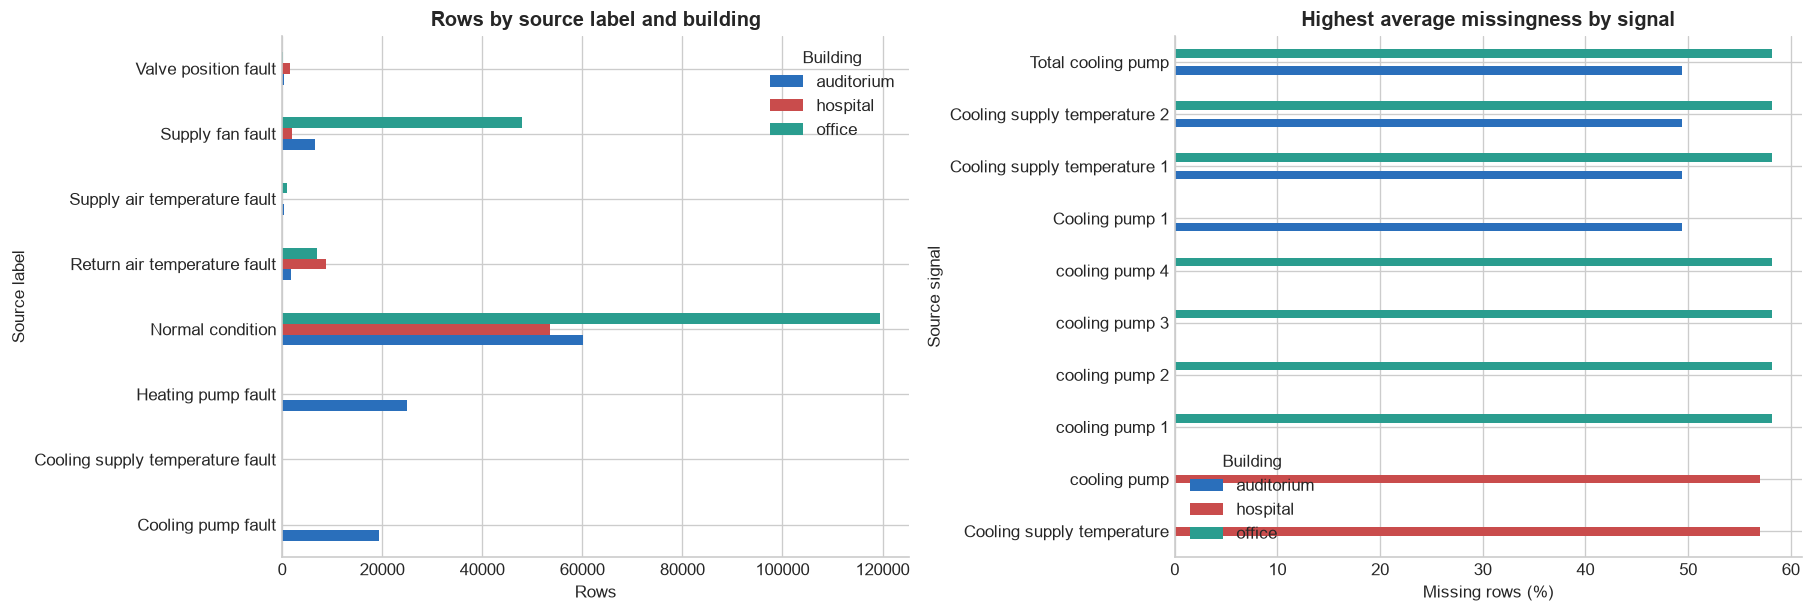

,building,label,rows
2,auditorium,Normal condition,60219
1,auditorium,Heating pump fault,24890
0,auditorium,Cooling pump fault,19292
5,auditorium,Supply fan fault,6525
3,auditorium,Return air temperature fault,1734
4,auditorium,Supply air temperature fault,404
6,auditorium,Valve position fault,311
8,hospital,Normal condition,53491
9,hospital,Return air temperature fault,8756
11,hospital,Supply fan fault,1921


In [2]:
clean_meta = pd.read_csv(CLEAN_FILE, usecols=['building', 'ahu', 'timestamp', 'label'], low_memory=False)
clean_meta['timestamp'] = pd.to_datetime(clean_meta['timestamp'], errors='raise')

summary = (
    clean_meta.groupby('building')
    .agg(rows=('building', 'size'), ahus=('ahu', 'nunique'), start=('timestamp', 'min'), end=('timestamp', 'max'))
    .reset_index()
)
label_counts = clean_meta.groupby(['building', 'label']).size().rename('rows').reset_index()
summary['normal_rows'] = summary['building'].map(label_counts.loc[label_counts['label'].eq('Normal condition')].set_index('building')['rows'])
summary['fault_rows'] = summary['rows'] - summary['normal_rows']
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
label_plot = label_counts.pivot(index='label', columns='building', values='rows').fillna(0)
label_plot.plot.barh(ax=axes[0], color=[BUILDING_COLORS.get(c, '#777777') for c in label_plot.columns])
axes[0].set_title('Rows by source label and building')
axes[0].set_xlabel('Rows')
axes[0].set_ylabel('Source label')
axes[0].legend(title='Building')

missingness = pd.read_csv(AUDIT_DIR / 'audit_missingness.csv', low_memory=False)
missingness = missingness.loc[missingness['building'].isin(BUILDING_COLORS)].copy()
top_missing = missingness.groupby('column')['missing_rate'].mean().nlargest(10).index
plot_missing = missingness[missingness['column'].isin(top_missing)].pivot(index='column', columns='building', values='missing_rate').fillna(0)
plot_missing.sort_values(plot_missing.columns[0]).mul(100).plot.barh(ax=axes[1], color=[BUILDING_COLORS.get(c, '#777777') for c in plot_missing.columns])
axes[1].set_title('Highest average missingness by signal')
axes[1].set_xlabel('Missing rows (%)')
axes[1].set_ylabel('Source signal')
axes[1].legend(title='Building')
plt.show()

display(label_counts.sort_values(['building', 'rows'], ascending=[True, False]))

## 2. Cleaning and duplicate policy

The headline table excludes every row belonging to an ambiguous `building + AHU + timestamp` key. The sensitivity table retains those rows with a duplicate flag. Neither policy silently selects the first row or averages conflicting observations. This section reports the actual saved policy counts rather than repeating the cleaning operation in the notebook.

,Policy,Rows in output,Rows excluded,Duplicate keys in output,Placeholder cells converted,Non-finite cells converted
0,exclude_ambiguous_keys,354587,368,0,8208,0
1,retain_flagged_keys,354955,0,184,8208,0


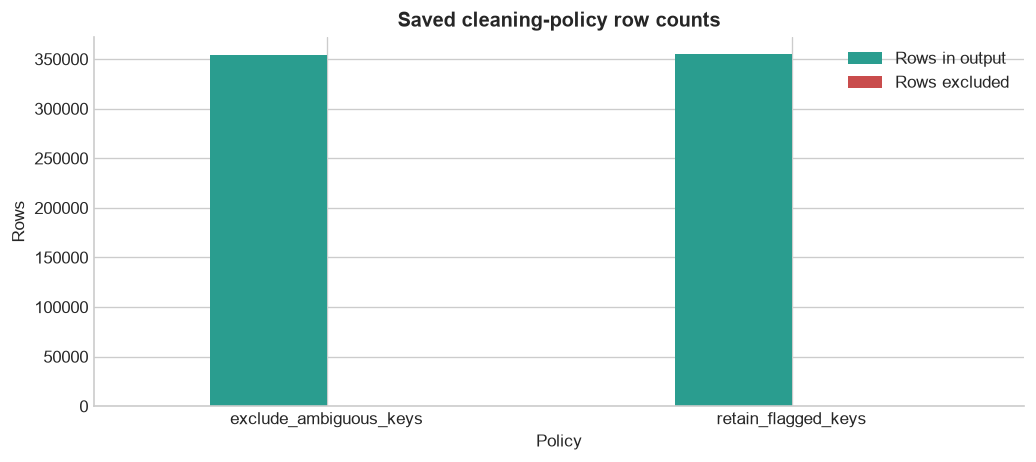

In [3]:
clean_manifest = read_json(CLEAN_MANIFEST)
policy_rows = []
for policy_name, policy in clean_manifest['policies'].items():
    policy_rows.append({
        'Policy': policy_name,
        'Rows in output': policy['output_rows'],
        'Rows excluded': policy['rows_excluded'],
        'Duplicate keys in output': policy['output_duplicate_key_count'],
        'Placeholder cells converted': policy['placeholder_cells_converted'],
        'Non-finite cells converted': policy['nonfinite_cells_converted'],
    })
policy_table = pd.DataFrame(policy_rows)
display(policy_table)

fig, axis = plt.subplots(figsize=(10, 4))
policy_table.set_index('Policy')[['Rows in output', 'Rows excluded']].plot.bar(ax=axis, color=['#2a9d8f', '#c94c4c'])
axis.set_title('Saved cleaning-policy row counts')
axis.set_ylabel('Rows')
axis.tick_params(axis='x', rotation=0)
plt.show()

## 3. Shared feature engineering and shortcut audit

All three buildings use the same canonical feature-generation implementation. The feature manifest records raw sensor, relationship and past-only temporal features. The shortcut audit is a review aid: a flag means a feature deserves investigation, not that it is automatically invalid or removed.

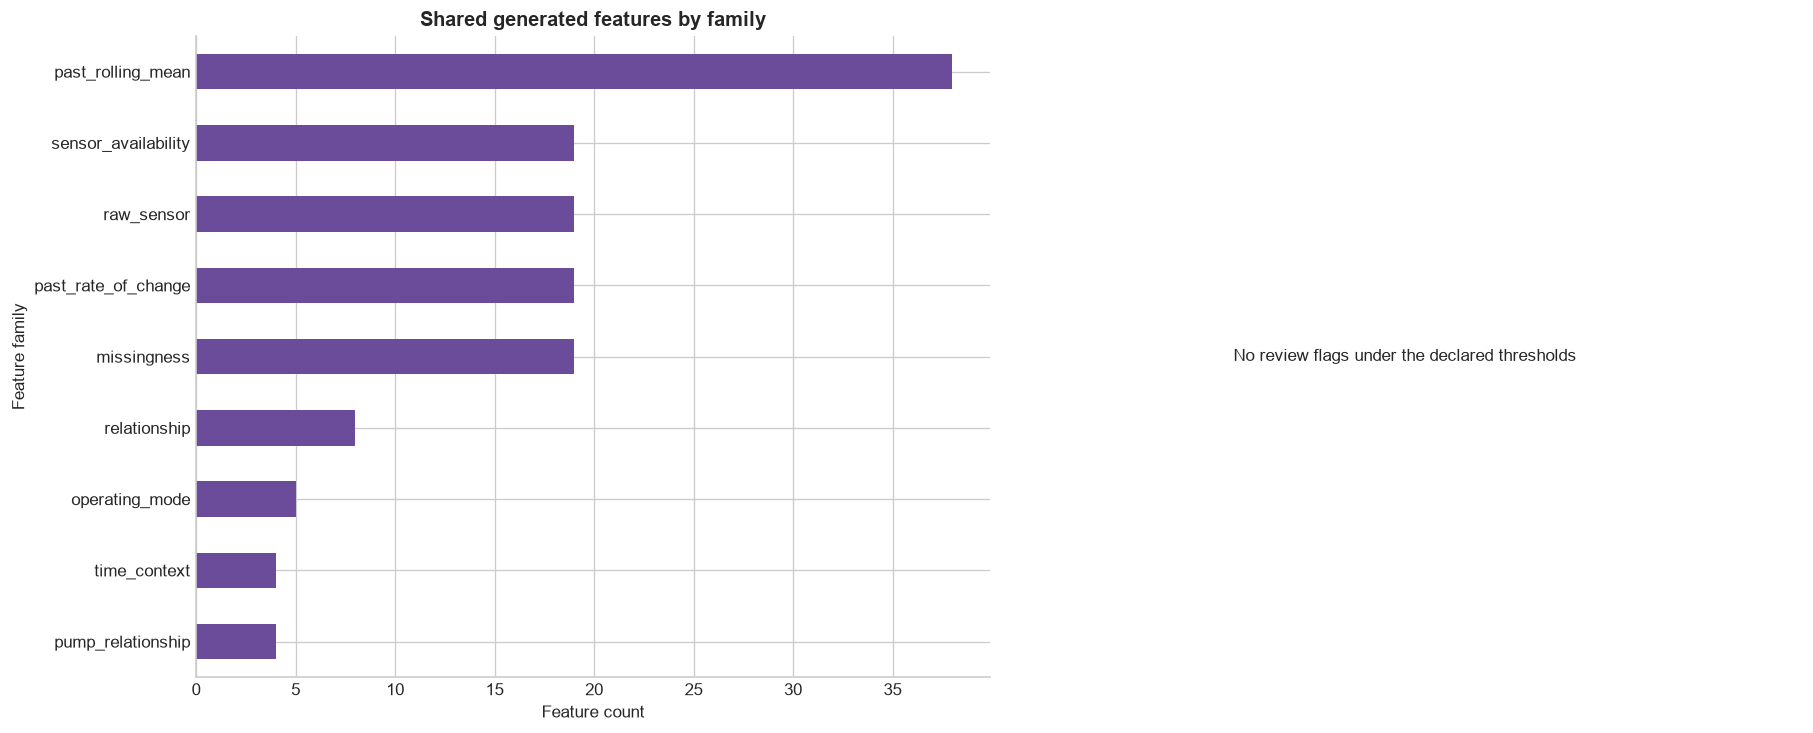

,Feature manifest item,Count
0,Physical-signal features,88
1,Operational-context features,135
2,Shortcut review flags,0


,variant,feature,family,missing_rate_gap,value_auc,review_required


In [4]:
feature_manifest = read_json(FEATURE_MANIFEST)
lineage = pd.read_csv(LINEAGE_FILE, low_memory=False)
shortcut = pd.read_csv(SHORTCUT_FILE, low_memory=False)
shortcut['review_required'] = (shortcut['missing_rate_gap'].abs() >= 0.25) | (shortcut['value_auc'].sub(0.5).abs() >= 0.25)
family_counts = lineage.groupby('family').size().sort_values()
review = shortcut.loc[shortcut['review_required']].copy()
review['separation'] = np.maximum(review['missing_rate_gap'].abs(), review['value_auc'].sub(0.5).abs())
review = review.sort_values('separation', ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
family_counts.plot.barh(ax=axes[0], color='#6b4c9a')
axes[0].set_title('Shared generated features by family')
axes[0].set_xlabel('Feature count')
axes[0].set_ylabel('Feature family')
if review.empty:
    axes[1].text(0.5, 0.5, 'No review flags under the declared thresholds', ha='center', va='center')
    axes[1].set_axis_off()
else:
    review.sort_values('separation').plot.barh(x='feature', y='separation', ax=axes[1], color='#c94c4c', legend=False)
    axes[1].axvline(0.25, color='#555555', linestyle='--', linewidth=1)
    axes[1].set_title('Largest shortcut-audit separations')
    axes[1].set_xlabel('Absolute gap from neutral separation')
    axes[1].set_ylabel('Feature')
plt.show()

display(pd.DataFrame({
    'Feature manifest item': ['Physical-signal features', 'Operational-context features', 'Shortcut review flags'],
    'Count': [feature_manifest['feature_counts']['physical_signal'], feature_manifest['feature_counts']['operational_context'], int(shortcut['review_required'].sum())],
}))
display(review[['variant', 'feature', 'family', 'missing_rate_gap', 'value_auc', 'review_required']])

## 4. Descriptive normal-operation patterns across all buildings

The following profiles use only rows labelled `Normal condition`. They are calculated from the saved shared feature table for this explanatory view; they do not fit a detector. The mode labels come from the saved operating-mode indicators. Missing values are left missing for profile means and are not treated as faults.

Normal rows used for descriptive profiles: 233,112
Normal rows by building:


,rows
building,
auditorium,60219
hospital,53491
office,119402


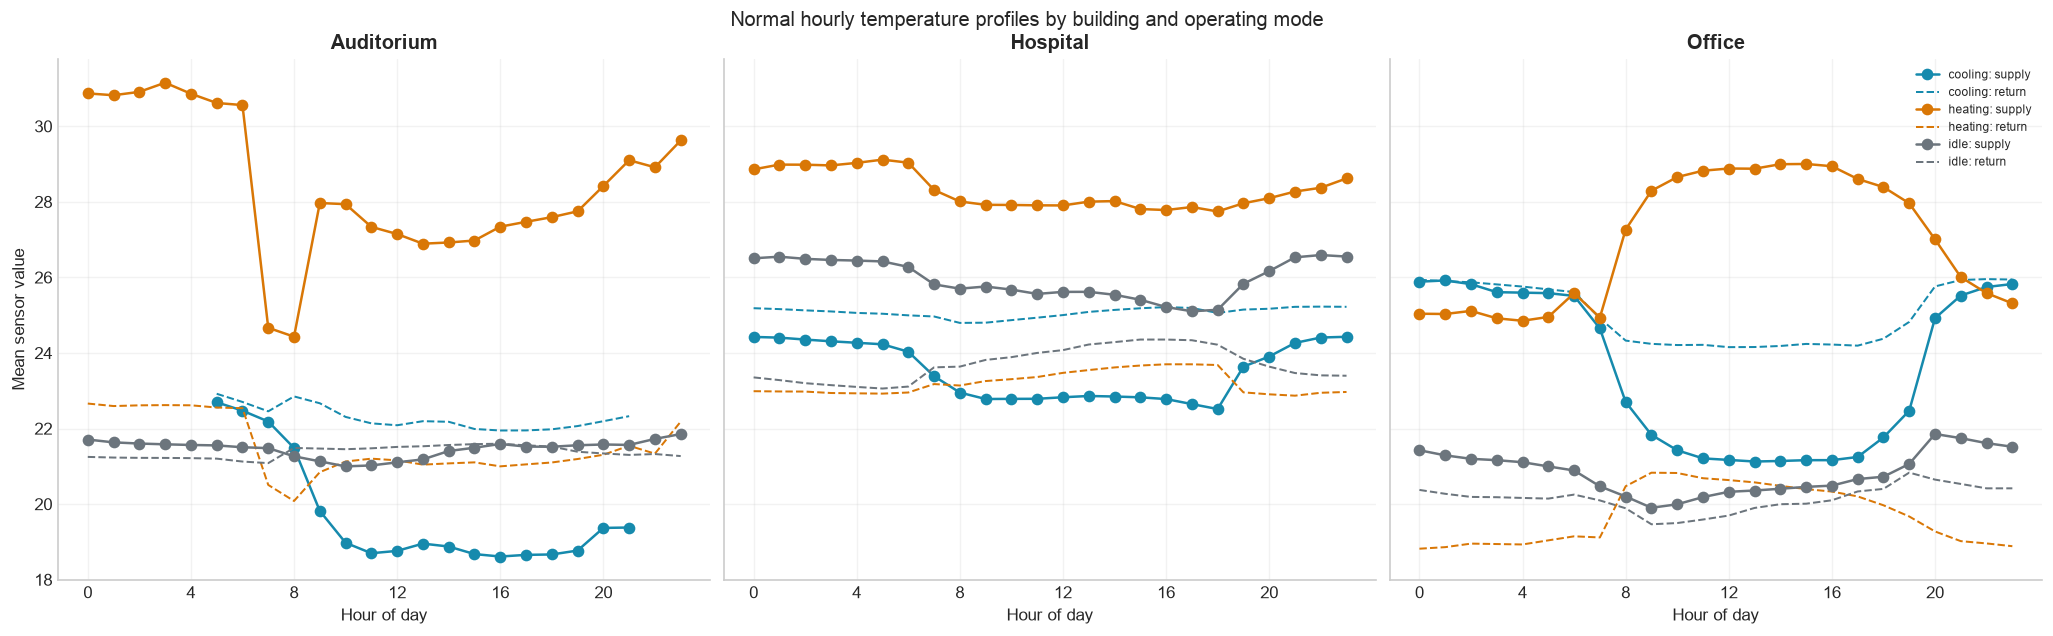

In [5]:
feature_header = pd.read_csv(FEATURE_FILE, nrows=0).columns.tolist()
profile_columns = ['building', 'ahu', 'timestamp', 'label', 'sensor__setpoint_temperature', 'sensor__return_temperature', 'sensor__supply_air_temperature', 'sensor__supply_fan', 'sensor__valve_position', 'sensor__heating_pump_total', 'sensor__cooling_pump_total', 'mode__heating_active', 'mode__cooling_active', 'mode__mixed_active', 'mode__idle', 'mode__unknown']
profile_columns = [column for column in profile_columns if column in feature_header]
features = pd.read_csv(FEATURE_FILE, usecols=profile_columns, low_memory=False)
features['timestamp'] = pd.to_datetime(features['timestamp'], errors='raise')
mode_columns = ['mode__heating_active', 'mode__cooling_active', 'mode__mixed_active', 'mode__idle']
mode_names = ['heating', 'cooling', 'mixed', 'idle']
mode_matrix = features[mode_columns].fillna(0).to_numpy()
features['operating_mode'] = np.where(mode_matrix.max(axis=1) == 0, 'unknown', np.array(mode_names)[mode_matrix.argmax(axis=1)])
features['hour'] = features['timestamp'].dt.hour
normal = features.loc[features['label'].eq('Normal condition')].copy()
print(f'Normal rows used for descriptive profiles: {len(normal):,}')
print('Normal rows by building:')
display(normal.groupby('building').size().rename('rows').to_frame())

profile = (
    normal.groupby(['building', 'operating_mode', 'hour'], dropna=False)
    [['sensor__supply_air_temperature', 'sensor__return_temperature']]
    .mean()
    .reset_index()
)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True, constrained_layout=True)
for axis, building in zip(axes, BUILDING_COLORS):
    subset = profile[profile['building'].eq(building)]
    for mode, mode_group in subset.groupby('operating_mode'):
        axis.plot(mode_group['hour'], mode_group['sensor__supply_air_temperature'], marker='o', linewidth=1.5, color=MODE_COLORS.get(mode, '#777777'), label=f'{mode}: supply')
        axis.plot(mode_group['hour'], mode_group['sensor__return_temperature'], linestyle='--', linewidth=1.2, color=MODE_COLORS.get(mode, '#777777'), label=f'{mode}: return')
    axis.set_title(building.title())
    axis.set_xlabel('Hour of day')
    axis.set_xticks(range(0, 24, 4))
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Mean sensor value')
axes[-1].legend(fontsize=7, loc='best')
fig.suptitle('Normal hourly temperature profiles by building and operating mode', y=1.03)
plt.show()

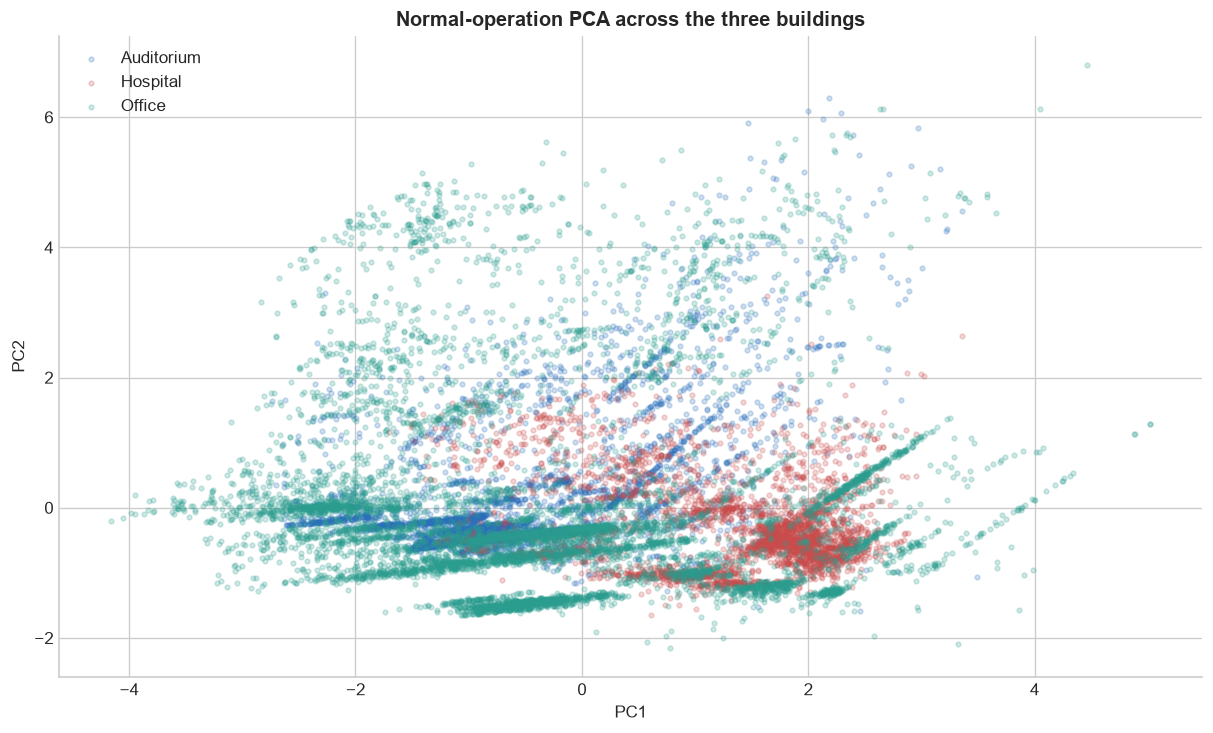

PCA features used: 7; rows sampled: 15,000


In [6]:
pca_columns = ['sensor__setpoint_temperature', 'sensor__return_temperature', 'sensor__supply_air_temperature', 'sensor__supply_fan', 'sensor__valve_position', 'sensor__heating_pump_total', 'sensor__cooling_pump_total']
pca_input = normal[['building', 'ahu', 'timestamp', *pca_columns]].copy()
pca_input = pca_input.sample(min(15000, len(pca_input)), random_state=42)
valid_columns = [column for column in pca_columns if pca_input[column].notna().sum() > 1 and pca_input[column].nunique(dropna=True) > 1]
if len(valid_columns) >= 2:
    matrix = pca_input[valid_columns].apply(pd.to_numeric, errors='coerce')
    matrix = matrix.fillna(matrix.median())
    coordinates = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(matrix))
    pca_input['pc1'], pca_input['pc2'] = coordinates[:, 0], coordinates[:, 1]
    fig, axis = plt.subplots(figsize=(10, 6), constrained_layout=True)
    for building, group in pca_input.groupby('building'):
        axis.scatter(group['pc1'], group['pc2'], s=8, alpha=0.22, color=BUILDING_COLORS[building], label=building.title())
    axis.set_title('Normal-operation PCA across the three buildings')
    axis.set_xlabel('PC1')
    axis.set_ylabel('PC2')
    axis.legend()
    plt.show()
    print(f'PCA features used: {len(valid_columns)}; rows sampled: {len(pca_input):,}')
else:
    print('PCA skipped because fewer than two variable sensor columns were available.')

## Interpretation

This walkthrough establishes the data context used by later notebooks: all three buildings are represented in one canonical cleaned table; duplicate handling is explicit; shared features are generated once and reused; and normal operation differs by building, hour and operating mode. These descriptive patterns motivate building-aware splits and held-out evaluation. They do not by themselves prove that a model will generalise across buildings.